# Entangled Futures
## Quantum kernels for county-level outage escalation screening

**Participant:** Kamilah Sanders  
**Category:** Rising Star  
**Track:** Quantum Machine Learning

### Research question

During an ongoing reported outage, can recent outage counts and previously
issued storm warnings help rank county-hours by the likelihood of a substantial
increase in reported customer outages 60–75 minutes later?

### Why This Matters

When electricity outages worsen, communities may need additional support to keep people safe, fed, and connected. Emergency coordinators must decide where to focus attention and prepare resources, often with incomplete information.

This project investigates whether outage histories and previously issued storm warnings can help identify places where reported outages may escalate. The intended purpose is to give coordinators more time to investigate local needs and organize support.

Outage counts indicate electricity disruption; they do not tell us who is suffering or how well a community is supporting its residents. A useful warning would therefore prompt further assessment, informed by local knowledge and community relationships.

This initial feasibility study evaluates whether outage histories and previously issued weather warnings could provide useful information for emergency coordination. It examines prediction performance and limitations; it does not evaluate coordination decisions or outcomes for people.

### Experiment

- ORNL EAGLE-I outage records: South Carolina, 2022.
- Escalation: an increase of at least 500 customers **and** 50%, present
  at both 60 and 75 minutes after prediction.
- Eligibility: positive reports at every 15-minute interval from two hours
  before prediction through 75 minutes afterward.
- Inputs: four historical outage counts transformed with log(1 + count),
  plus indicators for recent severe-thunderstorm and tornado warnings.
- Warning information: original county codes and original message times.
  Warnings must have been issued 15–120 minutes before prediction.
- Chronological training, validation, and final-test periods, with gaps
  between partitions.
- Quantum and conventional SVMs share the same 639 training examples.
  Additional conventional models use the full training partition.
- Quantum calculations use a six-qubit statevector simulator.

### Interpretation

The quantum model showed a small observed improvement over its matched
conventional SVM comparison on the final test. A conventional random forest
performed better overall. This experiment does not establish quantum advantage
or operational readiness.

The alert-budget evaluation retrospectively ranks a batch of county-hours.
It is not a deployed alert threshold or a guaranteed one-hour warning.

Eligibility depends on future reporting completeness and positive counts,
so results apply to this selected retrospective sample, not all county-hours
or all outage onsets. County-hours may share the same underlying storm.

Only two eligible final-test windows had a recent warning of the selected
types, and neither escalated. The warning rule's earlier fixed-budget result
included randomly selected unwarned windows. Its actual final-test warning
coverage was two alerts and zero detections.

### Sources and acknowledgments

- ORNL EAGLE-I dataset:
  https://doi.org/10.6084/m9.figshare.24237376
- Dataset description:
  https://doi.org/10.1038/s41597-024-03095-5
- Iowa Environmental Mesonet NWS warning archive:
  https://mesonet.agron.iastate.edu/info/datasets/vtec.html
- Method adapted from the hackathon's QML_1_Lecture.ipynb:
  https://github.com/iq-hackathon/IQ-Hackathon-Fall-2026-Beginners

AI assistance was used for code development, debugging, and interpretation.


## Installation
Run this cell first.

In [1]:
%pip install -q qiskit qiskit-machine-learning scikit-learn numpy pandas matplotlib

In [2]:
import io
import re
import json
import zipfile
import urllib.request
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.parse import urlencode

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV


In [3]:
import importlib.metadata

for package in [
    "qiskit", "qiskit-machine-learning", "scikit-learn",
    "numpy", "pandas", "matplotlib",
]:
    print(package, importlib.metadata.version(package))


qiskit 2.6.1
qiskit-machine-learning 0.9.1
scikit-learn 1.6.1
numpy 2.1.3
pandas 2.2.3
matplotlib 3.10.0


## Data retrieval and reporting-quality checks

In [4]:
import json
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd

# Find the official annual data file.
with urllib.request.urlopen(
    "https://api.figshare.com/v2/articles/24237376", timeout=120
) as response:
    metadata = json.load(response)

annual_file = next(
    f for f in metadata["files"]
    if f["name"].lower() == "eaglei_outages_2022.csv"
)

local_file = Path("/content/eaglei_outages_2022.csv")

if not local_file.exists() or local_file.stat().st_size != annual_file["size"]:
    print("Downloading the 2022 file. This may take several minutes…")
    temporary_file = local_file.with_suffix(".download")
    urllib.request.urlretrieve(annual_file["download_url"], temporary_file)
    temporary_file.replace(local_file)

print("Reading South Carolina records…")

parts = []
for chunk in pd.read_csv(local_file, chunksize=500_000):
    chunk.columns = chunk.columns.str.strip().str.lower()
    selected = chunk.loc[
        chunk["state"].astype(str).str.strip().str.lower()
        .isin(["south carolina", "sc"])
    ]
    if not selected.empty:
        parts.append(selected.copy())

if not parts:
    raise ValueError("No South Carolina records found.")

outages_sc = pd.concat(parts, ignore_index=True)
count_column = (
    "customers_out" if "customers_out" in outages_sc.columns else "sum"
)

outages_sc["time"] = pd.to_datetime(
    outages_sc["run_start_time"], format="mixed",
    utc=True, errors="coerce"
)
outages_sc["out"] = pd.to_numeric(
    outages_sc[count_column], errors="coerce"
)
outages_sc = outages_sc.dropna(subset=["fips_code", "time", "out"])

# Remove conflicting duplicate reports rather than choosing one.
keys = ["fips_code", "time"]
conflicting = (
    outages_sc.groupby(keys)["out"].transform("nunique") > 1
)
conflict_rows = int(conflicting.sum())
outages_sc = (
    outages_sc.loc[~conflicting]
    .drop_duplicates(keys)
    .sort_values(keys)
)

summaries = []

for minimum_rise in [100, 500, 1000]:
    eligible_total = 0
    escalation_total = 0
    episode_total = 0
    affected_counties = set()
    episode_dates = set()

    for fips, county in outages_sc.groupby("fips_code"):
        # Missing reports remain missing. Never replace them with zero.
        counts = county.set_index("time")["out"].asfreq("15min")

        # At time t, require every report from t-2h through t+1h15m.
        complete = (
            counts.notna().rolling(14, min_periods=14).sum()
            .shift(-5).eq(14)
        )
        eligible = complete & (counts.index.minute == 0)

        # Proposed escalation:
        # at least 50% AND the specified absolute increase,
        # present at both one hour and 75 minutes ahead.
        required_rise = np.maximum(minimum_rise, 0.5 * counts)
        escalation = (
            eligible
            & (counts.shift(-4) - counts >= required_rise)
            & (counts.shift(-5) - counts >= required_rise)
        )

        eligible_total += int(eligible.sum())
        escalation_total += int(escalation.sum())

        times = counts.index[escalation.to_numpy()]
        if len(times):
            affected_counties.add(fips)

            # Conservative grouping: flagged hours separated by
            # no more than 24h belong to one county episode.
            starts = np.r_[
                True,
                np.diff(times.asi8) > pd.Timedelta("24h").value
            ]
            episode_total += int(starts.sum())
            episode_dates.update(times[starts].date)

    summaries.append({
        "Minimum customer increase": minimum_rise,
        "Complete eligible windows": eligible_total,
        "Escalation windows": escalation_total,
        "Other eligible windows": eligible_total - escalation_total,
        "Grouped county episodes": episode_total,
        "Counties with escalations": len(affected_counties),
        "Distinct episode-start dates": len(episode_dates),
    })

audit_table = pd.DataFrame(summaries)

print(f"\nSouth Carolina records retained: {len(outages_sc):,}")
print(f"Conflicting duplicate rows excluded: {conflict_rows:,}")
print("\nFEASIBILITY CHECK")
print(audit_table.to_string(index=False))

Reading South Carolina records…

South Carolina records retained: 539,068
Conflicting duplicate rows excluded: 0

FEASIBILITY CHECK
 Minimum customer increase  Complete eligible windows  Escalation windows  Other eligible windows  Grouped county episodes  Counties with escalations  Distinct episode-start dates
                       100                      78020                1182                   76838                      721                         45                           244
                       500                      78020                 506                   77514                      354                         41                           155
                      1000                      78020                 282                   77738                      206                         34                            93


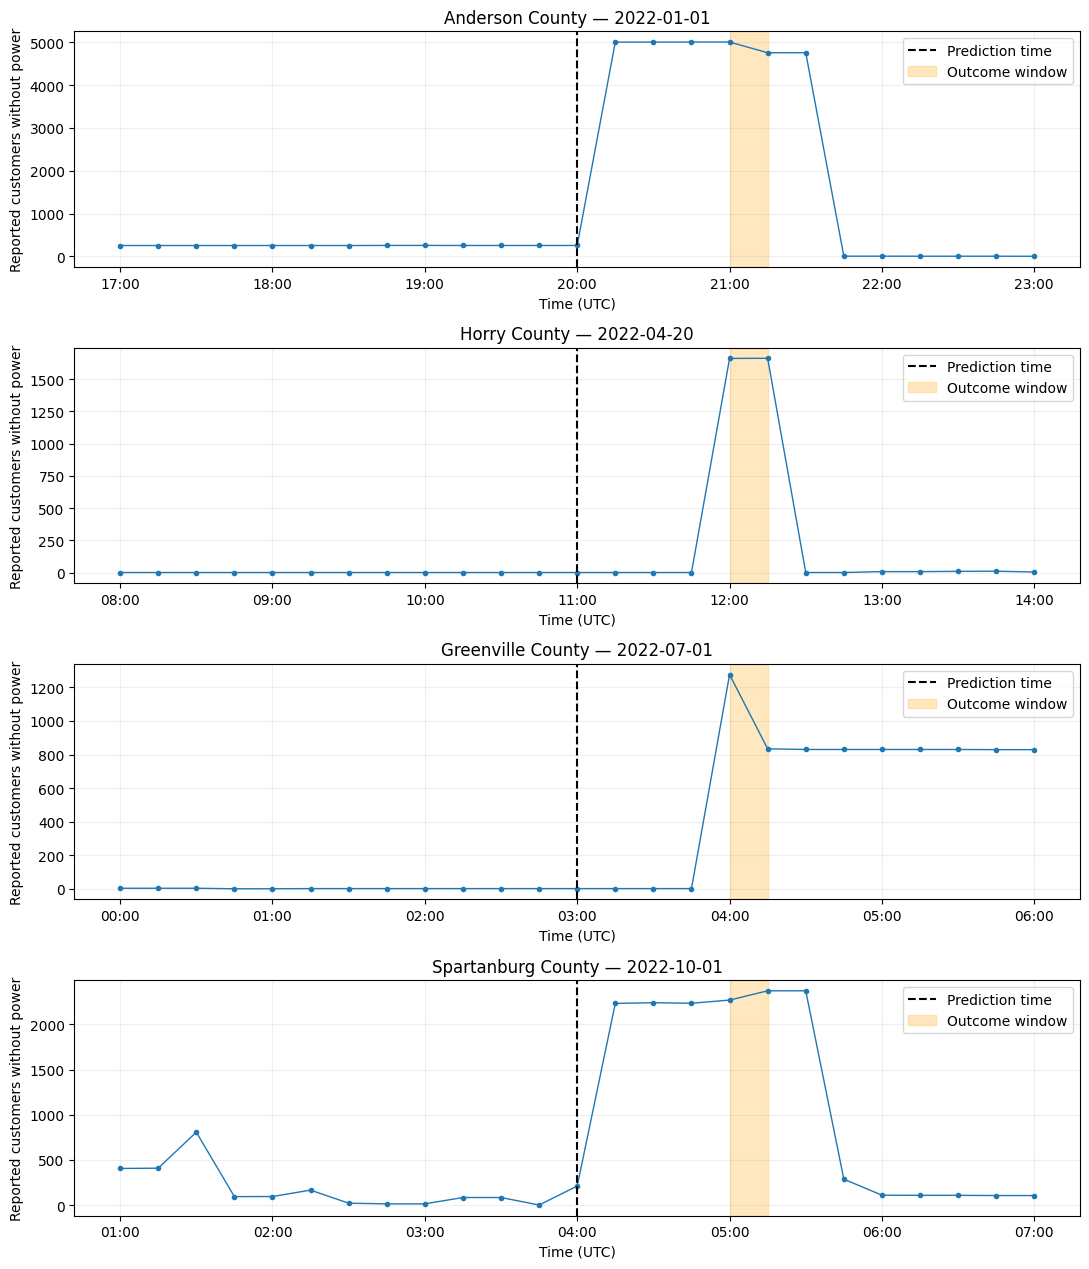

     county                      time
   Anderson 2022-01-01 20:00:00+00:00
      Horry 2022-04-20 11:00:00+00:00
 Greenville 2022-07-01 03:00:00+00:00
Spartanburg 2022-10-01 04:00:00+00:00


In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

candidates = []

for fips, county in outages_sc.groupby("fips_code"):
    counts = county.set_index("time")["out"].asfreq("15min")

    complete = (
        counts.notna().rolling(14, min_periods=14).sum()
        .shift(-5).eq(14)
    )
    eligible = complete & (counts.index.minute == 0)
    required_rise = np.maximum(500, 0.5 * counts)

    escalation = (
        eligible
        & (counts.shift(-4) - counts >= required_rise)
        & (counts.shift(-5) - counts >= required_rise)
    )

    for time in counts.index[escalation.to_numpy()]:
        candidates.append({
            "fips": fips,
            "county": county["county"].iloc[0],
            "time": time,
            "quarter": time.quarter,
        })

candidate_events = pd.DataFrame(candidates).sort_values(
    ["time", "fips"]
)
examples = candidate_events.drop_duplicates("quarter")

fig, axes = plt.subplots(
    len(examples), 1,
    figsize=(11, 3.2 * len(examples)),
    squeeze=False
)

for ax, (_, example) in zip(axes[:, 0], examples.iterrows()):
    county = outages_sc.loc[
        outages_sc["fips_code"] == example["fips"]
    ]
    counts = county.set_index("time")["out"].asfreq("15min")
    time = example["time"]

    timeline = counts.loc[
        time - pd.Timedelta(hours=3):
        time + pd.Timedelta(hours=3)
    ]

    ax.plot(timeline.index, timeline.values, marker=".", linewidth=1)
    ax.axvline(time, color="black", linestyle="--",
               label="Prediction time")
    ax.axvspan(
        time + pd.Timedelta(hours=1),
        time + pd.Timedelta(minutes=75),
        color="orange", alpha=0.25, label="Outcome window"
    )
    ax.set_title(
        f"{example['county']} County — {time:%Y-%m-%d}"
    )
    ax.set_ylabel("Reported customers without power")
    ax.set_xlabel("Time (UTC)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.legend(loc="best")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(examples[["county", "time"]].to_string(index=False))

In [6]:
timeline_rows = []

for _, example in examples.iterrows():
    county = outages_sc.loc[
        outages_sc["fips_code"] == example["fips"]
    ]
    counts = county.set_index("time")["out"].asfreq("15min")

    row = {
        "County": example["county"],
        "Date": str(example["time"].date()),
    }

    for minutes in [-120, -60, -30, 0, 15, 30, 45, 60, 75, 90, 120]:
        timestamp = example["time"] + pd.Timedelta(minutes=minutes)
        row[f"{minutes:+} min"] = counts.get(timestamp, np.nan)

    timeline_rows.append(row)

print(pd.DataFrame(timeline_rows).to_string(index=False))

     County       Date  -120 min  -60 min  -30 min  +0 min  +15 min  +30 min  +45 min  +60 min  +75 min  +90 min  +120 min
   Anderson 2022-01-01     253.0    255.0    254.0   254.0   5005.0   5006.0   5007.0   5007.0   4757.0   4757.0       4.0
      Horry 2022-04-20       0.0      0.0      0.0     0.0      0.0      0.0      0.0   1662.0   1663.0      0.0       7.0
 Greenville 2022-07-01       1.0      2.0      2.0     2.0      2.0      2.0      2.0   1276.0    834.0    830.0     830.0
Spartanburg 2022-10-01      94.0     13.0     83.0   210.0   2233.0   2241.0   2235.0   2270.0   2373.0   2373.0     109.0


In [7]:
print("Downloaded file:", annual_file["name"])
print("Original columns:", outages_sc.columns.tolist())
print("Rows with explicit zero counts:", int((outages_sc["out"] == 0).sum()))
print("Rows with negative counts:", int((outages_sc["out"] < 0).sum()))

print("\nExamples of zero-count source records:")
print(
    outages_sc.loc[
        outages_sc["out"] == 0,
        ["county", "run_start_time", count_column]
    ].head(8).to_string(index=False)
)

Downloaded file: eaglei_outages_2022.csv
Original columns: ['fips_code', 'county', 'state', 'customers_out', 'run_start_time', 'time', 'out']
Rows with explicit zero counts: 119358
Rows with negative counts: 0

Examples of zero-count source records:
   county      run_start_time  customers_out
Abbeville 2022-01-05 03:00:00              0
Abbeville 2022-01-12 18:45:00              0
Abbeville 2022-01-13 11:45:00              0
Abbeville 2022-01-15 14:45:00              0
Abbeville 2022-02-04 07:30:00              0
Abbeville 2022-02-08 17:45:00              0
Abbeville 2022-03-23 20:45:00              0
Abbeville 2022-04-01 05:45:00              0


In [8]:
sensitivity = []

for positive_only in [False, True]:
    eligible_count = 0
    escalation_count = 0
    episode_count = 0
    dates = set()

    for fips, county in outages_sc.groupby("fips_code"):
        counts = county.set_index("time")["out"].asfreq("15min")

        # This mask changes eligibility, not the original records.
        observed = counts.notna()
        if positive_only:
            observed = observed & counts.gt(0)

        complete = (
            observed.rolling(14, min_periods=14).sum()
            .shift(-5).eq(14)
        )
        eligible = complete & (counts.index.minute == 0)
        required_rise = np.maximum(500, 0.5 * counts)

        escalation = (
            eligible
            & (counts.shift(-4) - counts >= required_rise)
            & (counts.shift(-5) - counts >= required_rise)
        )

        eligible_count += int(eligible.sum())
        escalation_count += int(escalation.sum())

        times = counts.index[escalation.to_numpy()]
        if len(times):
            starts = np.r_[
                True,
                np.diff(times.asi8) > pd.Timedelta("24h").value
            ]
            episode_count += int(starts.sum())
            dates.update(times[starts].date)

    sensitivity.append({
        "Reporting requirement": (
            "All reports positive" if positive_only
            else "All reports present, including zeros"
        ),
        "Eligible windows": eligible_count,
        "Escalation windows": escalation_count,
        "Grouped county episodes": episode_count,
        "Episode-start dates": len(dates),
    })

print(pd.DataFrame(sensitivity).to_string(index=False))

               Reporting requirement  Eligible windows  Escalation windows  Grouped county episodes  Episode-start dates
All reports present, including zeros             78020                 506                      354                  155
                All reports positive             47849                 501                      350                  153


## Outcome construction and chronological split

In [9]:
window_parts = []

for fips, county in outages_sc.groupby("fips_code"):
    counts = county.set_index("time")["out"].asfreq("15min")

    # Require uninterrupted positive reports across history and outcome.
    complete = (
        counts.gt(0).rolling(14, min_periods=14).sum()
        .shift(-5).eq(14)
    )
    eligible = complete & (counts.index.minute == 0)
    required_rise = np.maximum(500, 0.5 * counts)

    windows = pd.DataFrame(index=counts.index)
    windows["county"] = county["county"].iloc[0]
    windows["fips"] = fips

    # Model inputs use only information available at prediction time.
    for minutes, steps in [(120, 8), (60, 4), (30, 2), (0, 0)]:
        windows[f"log_count_{minutes}m_ago"] = np.log1p(
            counts.shift(steps)
        )

    windows["escalation"] = (
        (counts.shift(-4) - counts >= required_rise)
        & (counts.shift(-5) - counts >= required_rise)
    ).astype(int)

    window_parts.append(windows.loc[eligible].copy())

sc_windows = pd.concat(window_parts).sort_index()
sc_windows.index.name = "prediction_time"

outage_features = [
    "log_count_120m_ago",
    "log_count_60m_ago",
    "log_count_30m_ago",
    "log_count_0m_ago",
]

# Leave a day between partitions to avoid overlapping windows.
sc_train = sc_windows.loc[sc_windows.index < "2022-06-30"].copy()
sc_validation = sc_windows.loc[
    (sc_windows.index >= "2022-07-01")
    & (sc_windows.index < "2022-09-30")
].copy()
sc_test = sc_windows.loc[sc_windows.index >= "2022-10-01"].copy()

for name, frame in [
    ("Training: January–June", sc_train),
    ("Validation: July–September", sc_validation),
    ("Final test: October–December", sc_test),
]:
    print(
        f"{name}: {len(frame):,} windows, "
        f"{frame['escalation'].sum():,} escalation windows"
    )

Training: January–June: 22,445 windows, 213 escalation windows
Validation: July–September: 12,323 windows, 135 escalation windows
Final test: October–December: 12,438 windows, 100 escalation windows


## Conventional outage-history comparisons

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

X_outage_train = sc_train[outage_features].to_numpy()
y_outage_train = sc_train["escalation"].to_numpy()

X_outage_validation = sc_validation[outage_features].to_numpy()
y_outage_validation = sc_validation["escalation"].to_numpy()

outage_baselines = {
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42,
        ),
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
}

# A simple comparison: change in log outage counts over 30 minutes.
validation_scores = {
    "Recent-increase rule": (
        X_outage_validation[:, 3] - X_outage_validation[:, 2]
    )
}

for name, model in outage_baselines.items():
    model.fit(X_outage_train, y_outage_train)
    validation_scores[name] = model.predict_proba(
        X_outage_validation
    )[:, 1]

alert_count = int(np.ceil(0.01 * len(sc_validation)))
validation_results = []

for name, scores in validation_scores.items():
    selected = np.argsort(-scores, kind="stable")[:alert_count]
    caught = int(y_outage_validation[selected].sum())

    validation_results.append({
        "Method": name,
        "Average precision": average_precision_score(
            y_outage_validation, scores
        ),
        "Alerts": alert_count,
        "Escalation windows caught": caught,
        "False alerts": alert_count - caught,
        "Percent of escalations caught": (
            100 * caught / y_outage_validation.sum()
        ),
    })

print(
    pd.DataFrame(validation_results).to_string(
        index=False, float_format=lambda x: f"{x:.3f}"
    )
)
print(
    "\nValidation escalation prevalence:",
    f"{100 * y_outage_validation.mean():.2f}%"
)
print("Final test data remains unused.")

              Method  Average precision  Alerts  Escalation windows caught  False alerts  Percent of escalations caught
Recent-increase rule              0.016     124                          3           121                          2.222
 Logistic regression              0.019     124                          3           121                          2.222
       Random forest              0.020     124                          3           121                          2.222

Validation escalation prevalence: 1.10%
Final test data remains unused.


## Historical weather-warning context

In [11]:
import io
from urllib.parse import urlencode

weather_parameters = {
    "accept": "csv",
    "sts": "2022-01-01T00:00Z",
    "ets": "2022-10-01T00:00Z",
    "location_group": "states",
    "states": "SC",
    "addsvs": "0",
}

weather_url = (
    "https://mesonet.agron.iastate.edu/"
    "cgi-bin/request/gis/watchwarn.py?"
    + urlencode(weather_parameters)
)

print("Downloading historical South Carolina weather alerts…")

with urllib.request.urlopen(weather_url, timeout=180) as response:
    weather_bytes = response.read()

weather_alerts = pd.read_csv(
    io.BytesIO(weather_bytes), dtype=str
)
weather_alerts.columns = (
    weather_alerts.columns.str.strip().str.upper()
)

print(f"\nDownloaded rows: {len(weather_alerts):,}")
print("\nAvailable columns:")
print(weather_alerts.columns.tolist())

inspection_columns = [
    column for column in [
        "WFO", "PHENOM", "TYPE", "SIG", "GTYPE",
        "NWS_UGC", "INIT_ISS", "INIT_EXP",
        "ISSUED", "EXPIRED", "PROD_ID"
    ]
    if column in weather_alerts.columns
]

print("\nExample records:")
print(
    weather_alerts[inspection_columns]
    .head(8).to_string(index=False)
)


Downloaded rows: 5,317

Available columns:
['WFO', 'UTC_ISSUE', 'UTC_EXPIRE', 'UTC_PRODISSUE', 'UTC_INIT_EXPIRE', 'PHENOMENA', 'GTYPE', 'SIGNIFICANCE', 'EVENTID', 'STATUS', 'UGC', 'AREA2D', 'UTC_UPDATED', 'HVTEC_NWSLI', 'HVTEC_SEVERITY', 'HVTEC_CAUSE', 'HVTEC_RECORD', 'IS_EMERGENCY', 'UTC_POLYGON_BEGIN', 'UTC_POLYGON_END', 'WINDTAG', 'HAILTAG', 'TORNADOTAG', 'DAMAGETAG', 'PRODUCT_ID', 'FCSTER', 'VTEC_YEAR']

Example records:
WFO GTYPE
CAE     P
CAE     P
CAE     P
CAE     P
CAE     P
CAE     P
CAE     P
CAE     P


In [12]:
storm_warnings = weather_alerts.loc[
    weather_alerts["PHENOMENA"].isin(["SV", "TO"])
    & weather_alerts["SIGNIFICANCE"].eq("W")
    & weather_alerts["GTYPE"].eq("P")
].copy()
print("Storm-warning polygon records:", len(storm_warnings))

Storm-warning polygon records: 590


In [13]:
import re
import json
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

cache_file = Path("/content/original_storm_warning_texts.json")
warning_text_cache = (
    json.loads(cache_file.read_text()) if cache_file.exists() else {}
)

product_ids = (
    storm_warnings["PRODUCT_ID"].dropna().unique().tolist()
)
pending = [p for p in product_ids if p not in warning_text_cache]

def fetch_warning(product_id):
    url = (
        "https://mesonet.agron.iastate.edu/api/1/nwstext/"
        + product_id
    )
    for attempt in range(2):
        try:
            with urllib.request.urlopen(url, timeout=45) as response:
                text = response.read().decode("utf-8", errors="replace")
            if "National Weather Service" not in text:
                raise ValueError("Response did not contain a warning message.")
            return product_id, text
        except Exception:
            if attempt == 1:
                raise

print(f"Original messages: {len(product_ids)}; downloads needed: {len(pending)}")
download_errors = []

with ThreadPoolExecutor(max_workers=3) as pool:
    jobs = {pool.submit(fetch_warning, p): p for p in pending}
    for number, job in enumerate(as_completed(jobs), 1):
        try:
            product_id, text = job.result()
            warning_text_cache[product_id] = text
        except Exception as error:
            download_errors.append((jobs[job], str(error)))

        if number % 50 == 0:
            cache_file.write_text(json.dumps(warning_text_cache))
            print(f"Processed {number}/{len(pending)} downloads")

cache_file.write_text(json.dumps(warning_text_cache))

if download_errors:
    print(download_errors[:5])
    raise RuntimeError("Some messages failed. Rerun this box to retry.")


new_warning_pattern = re.compile(
    r"/O\.NEW\.K([A-Z]{3})\.(SV|TO)\.W\.(\d{4})\."
)


Original messages: 590; downloads needed: 590
Processed 50/590 downloads
Processed 100/590 downloads
Processed 150/590 downloads
Processed 200/590 downloads
Processed 250/590 downloads
Processed 300/590 downloads
Processed 350/590 downloads
Processed 400/590 downloads
Processed 450/590 downloads
Processed 500/590 downloads
Processed 550/590 downloads


In [14]:
# Corrected pattern: works with the compacted message text.
ugc_pattern = re.compile(
    r"[A-Z]{2}[CZ]\d{3}(?:>\d{3})?-"
    r"(?:(?:[A-Z]{2}[CZ])?\d{3}(?:>\d{3})?-)*"
    r"\d{6}-"
)

def extract_sc_counties(segment):
    compact = re.sub(r"\s+", "", segment)
    counties = set()

    for group in ugc_pattern.findall(compact):
        prefix = None

        for token in group.rstrip("-").split("-")[:-1]:
            match = re.fullmatch(
                r"([A-Z]{2}[CZ])?(\d{3})(?:>(\d{3}))?", token
            )
            if not match:
                continue

            if match.group(1):
                prefix = match.group(1)

            first = int(match.group(2))
            last = int(match.group(3) or match.group(2))

            if prefix == "SCC":
                counties.update(
                    f"45{code:03d}" for code in range(first, last + 1)
                )

    return counties

# Check against the original message we manually inspected.
known_product = "202203161745-KCAE-WUUS52-SVRCAE"
assert {"45009", "45011"}.issubset(
    extract_sc_counties(warning_text_cache[known_product])
), "County extraction still needs correction."

warning_rows = []
unparsed_products = []

for product_id in product_ids:
    issued = pd.to_datetime(
        product_id[:12], format="%Y%m%d%H%M", utc=True
    )
    extracted = False

    for segment in warning_text_cache[product_id].split("$$"):
        events = new_warning_pattern.findall(segment)
        counties = extract_sc_counties(segment)

        for office, hazard, event_id in events:
            for fips in counties:
                warning_rows.append({
                    "fips": fips,
                    "issued": issued,
                    "hazard": hazard,
                    "event_key": f"{issued.year}-{office}-{hazard}-{event_id}",
                    "product_id": product_id,
                })
                extracted = True

    if not extracted:
        unparsed_products.append(product_id)

county_warnings = pd.DataFrame(warning_rows).drop_duplicates(
    ["fips", "event_key", "issued"]
)

print("Known Barnwell/Bamberg example: passed")
print("County-warning records extracted:", len(county_warnings))
print("Messages requiring review:", len(unparsed_products))
print("First messages requiring review:", unparsed_products[:5])
print("\nExamples:")
print(county_warnings.head(8).to_string(index=False))

Known Barnwell/Bamberg example: passed
County-warning records extracted: 1269
Messages requiring review: 60
First messages requiring review: ['202203162359-KCAE-WUUS52-SVRCAE', '202205062022-KCAE-WUUS52-SVRCAE', '202205062100-KCAE-WUUS52-SVRCAE', '202205012248-KCHS-WUUS52-SVRCHS', '202205062016-KCHS-WUUS52-SVRCHS']

Examples:
 fips                    issued hazard        event_key                      product_id
45011 2022-03-16 17:45:00+00:00     SV 2022-CAE-SV-0001 202203161745-KCAE-WUUS52-SVRCAE
45009 2022-03-16 17:45:00+00:00     SV 2022-CAE-SV-0001 202203161745-KCAE-WUUS52-SVRCAE
45075 2022-01-03 07:50:00+00:00     TO 2022-CAE-TO-0001 202201030750-KCAE-WFUS52-TORCAE
45009 2022-01-03 07:50:00+00:00     TO 2022-CAE-TO-0001 202201030750-KCAE-WFUS52-TORCAE
45011 2022-03-16 21:13:00+00:00     SV 2022-CAE-SV-0002 202203162113-KCAE-WUUS52-SVRCAE
45003 2022-04-05 18:55:00+00:00     TO 2022-CAE-TO-0002 202204051855-KCAE-WFUS52-TORCAE
45071 2022-04-05 19:09:00+00:00     TO 2022-CAE-TO-0003 

In [15]:
# Verify every unmatched message before excluding it.
unresolved = []
outside_states = Counter()

for product_id in unparsed_products:
    text = warning_text_cache[product_id]
    states = set(re.findall(r"\b([A-Z]{2})C\d{3}", text))

    if not states or "SC" in states:
        unresolved.append(product_id)
    else:
        for state in states:
            outside_states[state] += 1

print("Out-of-state messages by state:", dict(outside_states))
print("Unresolved messages:", len(unresolved))

if unresolved:
    print(unresolved[:5])
    raise RuntimeError("County extraction still requires review.")

# Add warning information using only original issuance times.
# Count warnings issued between 120 and 15 minutes before prediction.
def add_warning_context(frame):
    result = frame.copy()
    county_codes = (
        pd.to_numeric(result["fips"], errors="raise")
        .astype(int).astype(str).str.zfill(5)
    )
    prediction_times = result.index.asi8

    for hazard in ["SV", "TO"]:
        has_warning = np.zeros(len(result), dtype=np.int8)
        relevant = county_warnings.loc[
            county_warnings["hazard"] == hazard
        ]

        for fips in county_codes.unique():
            positions = np.flatnonzero(
                county_codes.to_numpy() == fips
            )
            issued = pd.DatetimeIndex(
                relevant.loc[relevant["fips"] == fips, "issued"]
            ).asi8
            issued = np.sort(issued)

            earliest = (
                prediction_times[positions]
                - pd.Timedelta(minutes=120).value
            )
            latest = (
                prediction_times[positions]
                - pd.Timedelta(minutes=15).value
            )

            number_issued = (
                np.searchsorted(issued, latest, side="right")
                - np.searchsorted(issued, earliest, side="left")
            )
            has_warning[positions] = (number_issued > 0).astype(int)

        result[f"recent_{hazard.lower()}_warning"] = has_warning

    return result

sc_train_weather = add_warning_context(sc_train)
sc_validation_weather = add_warning_context(sc_validation)

for name, frame in [
    ("TRAINING", sc_train_weather),
    ("VALIDATION", sc_validation_weather),
]:
    any_warning = (
        frame["recent_sv_warning"].eq(1)
        | frame["recent_to_warning"].eq(1)
    )

    summary = frame.assign(
        recent_warning=any_warning
    ).groupby("recent_warning").agg(
        windows=("escalation", "size"),
        escalations=("escalation", "sum"),
    )
    summary["escalation_percent"] = (
        100 * summary["escalations"] / summary["windows"]
    )

    print(f"\n{name}")
    print(summary.to_string(float_format=lambda x: f"{x:.3f}"))

print("\nFinal test period remains untouched.")

Out-of-state messages by state: {'GA': 15, 'NC': 47}
Unresolved messages: 0

TRAINING
                windows  escalations  escalation_percent
recent_warning                                          
False             22096          191               0.864
True                349           22               6.304

VALIDATION
                windows  escalations  escalation_percent
recent_warning                                          
False             12165          121               0.995
True                158           14               8.861

Final test period remains untouched.


In [16]:
from sklearn.base import clone

weather_features = outage_features + [
    "recent_sv_warning",
    "recent_to_warning",
]

weather_models = {}
comparison_scores = dict(validation_scores)

# Simple weather-only comparison.
comparison_scores["Recent-warning rule"] = (
    sc_validation_weather[
        ["recent_sv_warning", "recent_to_warning"]
    ].max(axis=1).to_numpy()
)

# Keep model settings unchanged; add the weather inputs.
for name, original_model in outage_baselines.items():
    model = clone(original_model)
    model.fit(
        sc_train_weather[weather_features].to_numpy(),
        y_outage_train,
    )
    weather_models[name] = model
    comparison_scores[f"{name} + warnings"] = model.predict_proba(
        sc_validation_weather[weather_features].to_numpy()
    )[:, 1]

# Resolve equal scores randomly using a fixed seed.
# The tie-breaker never uses the outcome labels.
tie_breaker = np.random.default_rng(42).random(
    len(y_outage_validation)
)

weather_comparison = []

for name, scores in comparison_scores.items():
    scores = np.asarray(scores)
    ranked = np.lexsort((tie_breaker, -scores))
    selected = ranked[:alert_count]
    caught = int(y_outage_validation[selected].sum())

    weather_comparison.append({
        "Method": name,
        "Average precision": average_precision_score(
            y_outage_validation, scores
        ),
        "Alerts": alert_count,
        "Escalation windows caught": caught,
        "False alerts": alert_count - caught,
        "Percent of escalations caught": (
            100 * caught / y_outage_validation.sum()
        ),
    })

print(
    pd.DataFrame(weather_comparison).to_string(
        index=False, float_format=lambda x: f"{x:.3f}"
    )
)
print("\nFinal test data remains unused.")

                        Method  Average precision  Alerts  Escalation windows caught  False alerts  Percent of escalations caught
          Recent-increase rule              0.016     124                          3           121                          2.222
           Logistic regression              0.019     124                          3           121                          2.222
                 Random forest              0.020     124                          3           121                          2.222
           Recent-warning rule              0.019     124                         13           111                          9.630
Logistic regression + warnings              0.028     124                         11           113                          8.148
      Random forest + warnings              0.024     124                          6           118                          4.444

Final test data remains unused.


## Matched training sample

In [17]:
# Keep all training escalation windows.
positive_training = sc_train_weather.loc[
    sc_train_weather["escalation"] == 1
]

# Sample two non-escalation windows per escalation window.
negative_training = sc_train_weather.loc[
    sc_train_weather["escalation"] == 0
].sample(
    n=2 * len(positive_training),
    random_state=42,
)

matched_training = pd.concat(
    [positive_training, negative_training]
).sort_index()

X_matched = matched_training[weather_features].to_numpy()
y_matched = matched_training["escalation"].to_numpy()

# Keep windows from the same calendar week together
# when selecting settings within the training period.
matched_groups = matched_training.index.strftime("%Y-%W").to_numpy()

print("Matched training windows:", len(matched_training))
print("Escalation windows:", int(y_matched.sum()))
print("Non-escalation windows:", int((y_matched == 0).sum()))
print("Inputs:", weather_features)
print("\nValidation remains unchanged; final test remains unused.")

Matched training windows: 639
Escalation windows: 213
Non-escalation windows: 426
Inputs: ['log_count_120m_ago', 'log_count_60m_ago', 'log_count_30m_ago', 'log_count_0m_ago', 'recent_sv_warning', 'recent_to_warning']

Validation remains unchanged; final test remains unused.


## Quantum and conventional SVM training

In [18]:
from sklearn.base import BaseEstimator
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedGroupKFold
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

# A callable similarity function for the quantum SVM.
class QuantumSimilarity(BaseEstimator):
    def __init__(self, bandwidth=0.1):
        self.bandwidth = bandwidth

    def __call__(self, X, Y):
        feature_map = zz_feature_map(
            feature_dimension=X.shape[1],
            reps=1,
            entanglement="linear",
        )
        kernel = FidelityStatevectorKernel(feature_map=feature_map)
        return kernel.evaluate(
            x_vec=self.bandwidth * X,
            y_vec=self.bandwidth * Y,
        )

grouped_cv = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=42
)
matched_folds = list(
    grouped_cv.split(X_matched, y_matched, matched_groups)
)

matched_models = {}

print("Training conventional SVM…")

classical_search = GridSearchCV(
    make_pipeline(
        MinMaxScaler(feature_range=(0, np.pi), clip=True),
        SVC(kernel="rbf", class_weight="balanced"),
    ),
    param_grid={
        "svc__C": [0.1, 1, 10],
        "svc__gamma": [0.01, 0.1, 1, "scale"],
    },
    scoring="average_precision",
    cv=matched_folds,
    n_jobs=-1,
)
classical_search.fit(X_matched, y_matched)
matched_models["Matched conventional SVM"] = classical_search

print("Training quantum-kernel SVM. This may take a few minutes…")

quantum_search = GridSearchCV(
    make_pipeline(
        MinMaxScaler(feature_range=(0, np.pi), clip=True),
        SVC(kernel=QuantumSimilarity(), class_weight="balanced"),
    ),
    param_grid={
        "svc__C": [0.1, 1, 10],
        "svc__kernel__bandwidth": [0.1, 0.3, 1.0],
    },
    scoring="average_precision",
    cv=matched_folds,
    n_jobs=1,
    verbose=1,
)
quantum_search.fit(X_matched, y_matched)
matched_models["Matched quantum-kernel SVM"] = quantum_search

for name, search in matched_models.items():
    print(f"\n{name}")
    print("Selected settings:", search.best_params_)

print("\nBoth models ready. No final-test predictions made.")

Training conventional SVM…
Training quantum-kernel SVM. This may take a few minutes…
Fitting 3 folds for each of 9 candidates, totalling 27 fits

Matched conventional SVM
Selected settings: {'svc__C': 10, 'svc__gamma': 0.1}

Matched quantum-kernel SVM
Selected settings: {'svc__C': 10, 'svc__kernel__bandwidth': 0.1}

Both models ready. No final-test predictions made.


In [19]:
X_weather_validation = (
    sc_validation_weather[weather_features].to_numpy()
)

for name, model in matched_models.items():
    print(f"Calculating validation scores: {name}…")
    comparison_scores[name] = model.decision_function(
        X_weather_validation
    )

all_validation_results = []

for name, scores in comparison_scores.items():
    scores = np.asarray(scores)
    ranked = np.lexsort((tie_breaker, -scores))
    selected = ranked[:alert_count]
    caught = int(y_outage_validation[selected].sum())

    all_validation_results.append({
        "Method": name,
        "Average precision": average_precision_score(
            y_outage_validation, scores
        ),
        "Alerts": alert_count,
        "Escalation windows caught": caught,
        "False alerts": alert_count - caught,
        "Percent of escalations caught": (
            100 * caught / y_outage_validation.sum()
        ),
    })

all_validation_results = pd.DataFrame(all_validation_results)

print(
    all_validation_results.to_string(
        index=False, float_format=lambda x: f"{x:.3f}"
    )
)
print("\nFinal test data remains unused.")

Calculating validation scores: Matched conventional SVM…
Calculating validation scores: Matched quantum-kernel SVM…
                        Method  Average precision  Alerts  Escalation windows caught  False alerts  Percent of escalations caught
          Recent-increase rule              0.016     124                          3           121                          2.222
           Logistic regression              0.019     124                          3           121                          2.222
                 Random forest              0.020     124                          3           121                          2.222
           Recent-warning rule              0.019     124                         13           111                          9.630
Logistic regression + warnings              0.028     124                         11           113                          8.148
      Random forest + warnings              0.024     124                          6           118      

## Historical weather-warning context

In [20]:
final_weather_parameters = {
    **weather_parameters,
    "sts": "2022-10-01T00:00Z",
    "ets": "2023-01-01T00:00Z",
}

final_weather_url = (
    "https://mesonet.agron.iastate.edu/"
    "cgi-bin/request/gis/watchwarn.py?"
    + urlencode(final_weather_parameters)
)

with urllib.request.urlopen(
    final_weather_url, timeout=180
) as response:
    final_weather_alerts = pd.read_csv(
        io.BytesIO(response.read()), dtype=str
    )

final_weather_alerts.columns = (
    final_weather_alerts.columns.str.strip().str.upper()
)

final_storm_warnings = final_weather_alerts.loc[
    final_weather_alerts["PHENOMENA"].isin(["SV", "TO"])
    & final_weather_alerts["SIGNIFICANCE"].eq("W")
    & final_weather_alerts["GTYPE"].eq("P")
].copy()

final_product_ids = (
    final_storm_warnings["PRODUCT_ID"]
    .dropna().unique().tolist()
)

print("Final-period alert records:", len(final_weather_alerts))
print("Original storm-warning messages:", len(final_product_ids))
print("Models and settings remain unchanged.")

Final-period alert records: 823
Original storm-warning messages: 5
Models and settings remain unchanged.


In [21]:
# Download the five original messages, using the existing cache.
for product_id in final_product_ids:
    if product_id not in warning_text_cache:
        key, text = fetch_warning(product_id)
        warning_text_cache[key] = text

cache_file.write_text(json.dumps(warning_text_cache))

# Apply exactly the same county-extraction rules.
final_warning_rows = []
final_unresolved = []
final_outside_sc = 0

for product_id in final_product_ids:
    text = warning_text_cache[product_id]
    issued = pd.to_datetime(
        product_id[:12], format="%Y%m%d%H%M", utc=True
    )
    extracted = False

    for segment in text.split("$$"):
        events = new_warning_pattern.findall(segment)
        counties = extract_sc_counties(segment)

        for office, hazard, event_id in events:
            for fips in counties:
                final_warning_rows.append({
                    "fips": fips,
                    "issued": issued,
                    "hazard": hazard,
                    "event_key": (
                        f"{issued.year}-{office}-{hazard}-{event_id}"
                    ),
                    "product_id": product_id,
                })
                extracted = True

    if not extracted:
        states = set(re.findall(r"\b([A-Z]{2})C\d{3}", text))
        if states and "SC" not in states:
            final_outside_sc += 1
        else:
            final_unresolved.append(product_id)

print("Final-period messages outside SC:", final_outside_sc)
print("Unresolved final-period messages:", len(final_unresolved))

if final_unresolved:
    print(final_unresolved)
    raise RuntimeError("Review these messages before final evaluation.")

# Retain earlier warnings so October 1 can use September 30 history.
if final_warning_rows:
    county_warnings = pd.concat(
        [county_warnings, pd.DataFrame(final_warning_rows)],
        ignore_index=True,
    ).drop_duplicates(["fips", "event_key", "issued"])

sc_test_weather = add_warning_context(sc_test)
X_final_basic = sc_test_weather[outage_features].to_numpy()
X_final_weather = sc_test_weather[weather_features].to_numpy()
y_final = sc_test_weather["escalation"].to_numpy()

recent_final_warning = sc_test_weather[
    ["recent_sv_warning", "recent_to_warning"]
].max(axis=1).to_numpy()

print("\nFinal-test windows:", len(y_final))
print("Escalation windows:", int(y_final.sum()))
print("Windows with a recent warning:", int(recent_final_warning.sum()))

# Score all previously defined approaches without changing settings.
final_scores = {
    "Recent-increase rule": (
        X_final_basic[:, 3] - X_final_basic[:, 2]
    ),
    "Recent-warning rule": recent_final_warning,
}

for name, model in outage_baselines.items():
    final_scores[name] = model.predict_proba(X_final_basic)[:, 1]

for name, model in weather_models.items():
    final_scores[f"{name} + warnings"] = model.predict_proba(
        X_final_weather
    )[:, 1]

for name, model in matched_models.items():
    print(f"Scoring final test: {name}…")
    final_scores[name] = model.decision_function(X_final_weather)

# Same 1% alert budget and label-independent tie-breaking.
final_alert_count = int(np.ceil(0.01 * len(y_final)))
final_tie_breaker = np.random.default_rng(42).random(len(y_final))
final_rows = []

for name, scores in final_scores.items():
    scores = np.asarray(scores)
    ranked = np.lexsort((final_tie_breaker, -scores))
    selected = ranked[:final_alert_count]
    caught = int(y_final[selected].sum())

    final_rows.append({
        "Method": name,
        "Average precision": average_precision_score(y_final, scores),
        "Alerts": final_alert_count,
        "Escalation windows caught": caught,
        "False alerts": final_alert_count - caught,
        "Percent of escalations caught": (
            100 * caught / y_final.sum()
        ),
    })

final_results = pd.DataFrame(final_rows)

print("\nFINAL TEST RESULTS")
print(
    final_results.to_string(
        index=False, float_format=lambda x: f"{x:.3f}"
    )
)
print(f"\nEscalation prevalence: {100 * y_final.mean():.3f}%")
print("Final evaluation complete. No models were retrained.")

Final-period messages outside SC: 0
Unresolved final-period messages: 0

Final-test windows: 12438
Escalation windows: 100
Windows with a recent warning: 2
Scoring final test: Matched conventional SVM…
Scoring final test: Matched quantum-kernel SVM…

FINAL TEST RESULTS
                        Method  Average precision  Alerts  Escalation windows caught  False alerts  Percent of escalations caught
          Recent-increase rule              0.029     125                          9           116                          9.000
           Recent-warning rule              0.008     125                          1           124                          1.000
           Logistic regression              0.034     125                          8           117                          8.000
                 Random forest              0.061     125                         15           110                         15.000
Logistic regression + warnings              0.031     125                       

## Final comparison figure

Actual recently warned test windows: 2
Escalations among those windows: 0


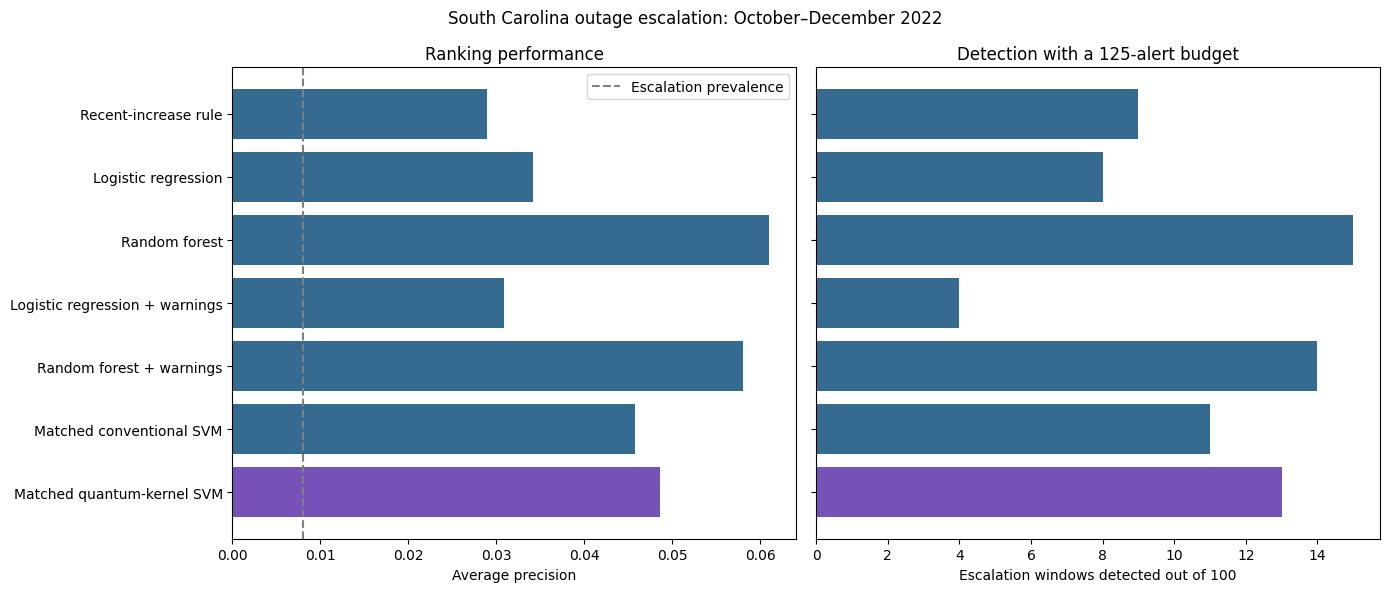

In [22]:
warned = recent_final_warning.astype(bool)
print("Actual recently warned test windows:", int(warned.sum()))
print("Escalations among those windows:", int(y_final[warned].sum()))

plot_results = final_results.set_index("Method").loc[
    [
        "Recent-increase rule",
        "Logistic regression",
        "Random forest",
        "Logistic regression + warnings",
        "Random forest + warnings",
        "Matched conventional SVM",
        "Matched quantum-kernel SVM",
    ]
]

colors = [
    "#7652B8" if "quantum" in name.lower() else "#356A91"
    for name in plot_results.index
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].barh(
    plot_results.index, plot_results["Average precision"], color=colors
)
axes[0].axvline(
    y_final.mean(), color="gray", linestyle="--",
    label="Escalation prevalence"
)
axes[0].set_xlabel("Average precision")
axes[0].set_title("Ranking performance")
axes[0].legend()

axes[1].barh(
    plot_results.index,
    plot_results["Escalation windows caught"],
    color=colors,
)
axes[1].set_xlabel("Escalation windows detected out of 100")
axes[1].set_title("Detection with a 125-alert budget")

axes[0].invert_yaxis()
fig.suptitle("South Carolina outage escalation: October–December 2022")
plt.tight_layout()
plt.savefig("Entangled_Futures_Final_Results.png", dpi=200, bbox_inches="tight")
plt.show()

In [23]:
print("Final test windows:", len(y_final))
print("Final test escalation windows:", int(y_final.sum()))

print(
    final_results.to_string(
        index=False, float_format=lambda x: f"{x:.3f}"
    )
)

Final test windows: 12438
Final test escalation windows: 100
                        Method  Average precision  Alerts  Escalation windows caught  False alerts  Percent of escalations caught
          Recent-increase rule              0.029     125                          9           116                          9.000
           Recent-warning rule              0.008     125                          1           124                          1.000
           Logistic regression              0.034     125                          8           117                          8.000
                 Random forest              0.061     125                         15           110                         15.000
Logistic regression + warnings              0.031     125                          4           121                          4.000
      Random forest + warnings              0.058     125                         14           111                         14.000
      Matched conventional SV